In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
data=pd.read_csv('QVI_data.csv')

In [3]:
df=pd.DataFrame(data)

In [4]:
df.shape

(264834, 12)

In [5]:
df

,LYLTY_CARD_NBR,DATE,STORE_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND,LIFESTAGE,PREMIUM_CUSTOMER
0,1000,10/17/2018,1,1,5,Natural Chip Compny SeaSalt175g,2,6.0,175,NATURAL,YOUNG SINGLES/COUPLES,Premium
1,1002,9/16/2018,1,2,58,Red Rock Deli Chikn&Garlic Aioli 150g,1,2.7,150,RRD,YOUNG SINGLES/COUPLES,Mainstream
2,1003,3/7/2019,1,3,52,Grain Waves Sour Cream&Chives 210G,1,3.6,210,GRNWVES,YOUNG FAMILIES,Budget
3,1003,3/8/2019,1,4,106,Natural ChipCo Hony Soy Chckn175g,1,3.0,175,NATURAL,YOUNG FAMILIES,Budget
4,1004,11/2/2018,1,5,96,WW Original Stacked Chips 160g,1,1.9,160,WOOLWORTHS,OLDER SINGLES/COUPLES,Mainstream
...,...,...,...,...,...,...,...,...,...,...,...,...
264829,2370701,12/8/2018,88,240378,24,Grain Waves Sweet Chilli 210g,2,7.2,210,GRNWVES,YOUNG FAMILIES,Mainstream
264830,2370751,10/1/2018,88,240394,60,Kettle Tortilla ChpsFeta&Garlic 150g,2,9.2,150,KETTLE,YOUNG FAMILIES,Premium
264831,2370961,10/24/2018,88,240480,70,Tyrrells Crisps Lightly Salted 165g,2,8.4,165,TYRRELLS,OLDER FAMILIES,Budget
264832,2370961,10/27/2018,88,240481,65,Old El Paso Salsa Dip Chnky Tom Ht300g,2,10.2,300,OLD,OLDER FAMILIES,Budget


In [6]:
df.columns

Index(['LYLTY_CARD_NBR', 'DATE', 'STORE_NBR', 'TXN_ID', 'PROD_NBR',
       'PROD_NAME', 'PROD_QTY', 'TOT_SALES', 'PACK_SIZE', 'BRAND', 'LIFESTAGE',
       'PREMIUM_CUSTOMER'],
      dtype='object')

In [7]:
df.isnull().sum()

LYLTY_CARD_NBR      0
DATE                0
STORE_NBR           0
TXN_ID              0
PROD_NBR            0
PROD_NAME           0
PROD_QTY            0
TOT_SALES           0
PACK_SIZE           0
BRAND               0
LIFESTAGE           0
PREMIUM_CUSTOMER    0
dtype: int64

In [8]:
df.dtypes

LYLTY_CARD_NBR        int64
DATE                 object
STORE_NBR             int64
TXN_ID                int64
PROD_NBR              int64
PROD_NAME            object
PROD_QTY              int64
TOT_SALES           float64
PACK_SIZE             int64
BRAND                object
LIFESTAGE            object
PREMIUM_CUSTOMER     object
dtype: object

In [9]:
pd.to_datetime(df['DATE'])

0        2018-10-17
1        2018-09-16
2        2019-03-07
3        2019-03-08
4        2018-11-02
            ...    
264829   2018-12-08
264830   2018-10-01
264831   2018-10-24
264832   2018-10-27
264833   2018-12-14
Name: DATE, Length: 264834, dtype: datetime64[ns]

In [10]:
df

,LYLTY_CARD_NBR,DATE,STORE_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND,LIFESTAGE,PREMIUM_CUSTOMER
0,1000,10/17/2018,1,1,5,Natural Chip Compny SeaSalt175g,2,6.0,175,NATURAL,YOUNG SINGLES/COUPLES,Premium
1,1002,9/16/2018,1,2,58,Red Rock Deli Chikn&Garlic Aioli 150g,1,2.7,150,RRD,YOUNG SINGLES/COUPLES,Mainstream
2,1003,3/7/2019,1,3,52,Grain Waves Sour Cream&Chives 210G,1,3.6,210,GRNWVES,YOUNG FAMILIES,Budget
3,1003,3/8/2019,1,4,106,Natural ChipCo Hony Soy Chckn175g,1,3.0,175,NATURAL,YOUNG FAMILIES,Budget
4,1004,11/2/2018,1,5,96,WW Original Stacked Chips 160g,1,1.9,160,WOOLWORTHS,OLDER SINGLES/COUPLES,Mainstream
...,...,...,...,...,...,...,...,...,...,...,...,...
264829,2370701,12/8/2018,88,240378,24,Grain Waves Sweet Chilli 210g,2,7.2,210,GRNWVES,YOUNG FAMILIES,Mainstream
264830,2370751,10/1/2018,88,240394,60,Kettle Tortilla ChpsFeta&Garlic 150g,2,9.2,150,KETTLE,YOUNG FAMILIES,Premium
264831,2370961,10/24/2018,88,240480,70,Tyrrells Crisps Lightly Salted 165g,2,8.4,165,TYRRELLS,OLDER FAMILIES,Budget
264832,2370961,10/27/2018,88,240481,65,Old El Paso Salsa Dip Chnky Tom Ht300g,2,10.2,300,OLD,OLDER FAMILIES,Budget


In [11]:
brand_sales = (
    df.groupby("BRAND", as_index=False)["TOT_SALES"]
      .sum()
      .sort_values("TOT_SALES", ascending=False)
      .reset_index(drop=True)
)

In [12]:
# Top third of brands
n_top = -(-len(brand_sales) // 3)   # round up
top = brand_sales.head(n_top)

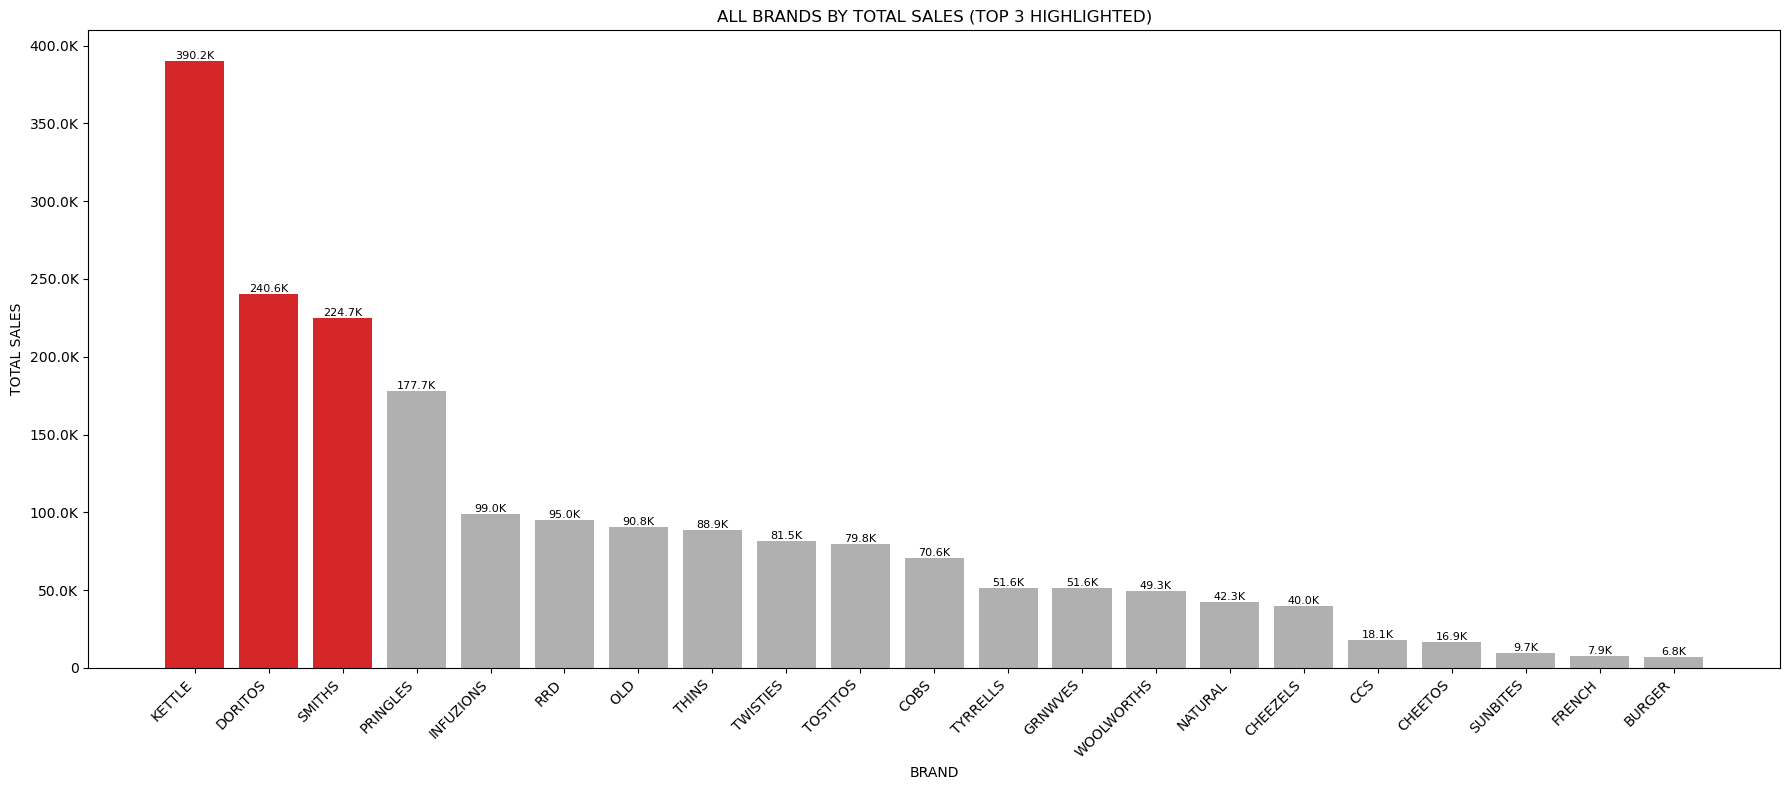

In [13]:


def fmt(v):
    if v >= 1_000_000:
        return f"{v/1_000_000:.1f}M"
    if v >= 1_000:
        return f"{v/1_000:.1f}K"
    return f"{v:.0f}"

# Total sales per brand, highest first
brand_sales = (
    df.groupby("BRAND", as_index=False)["TOT_SALES"]
      .sum()
      .sort_values("TOT_SALES", ascending=False)
      .reset_index(drop=True)
)

# Top 3 get a highlight color, the rest stay grey
colors = ["#d62728" if i < 3 else "#b0b0b0" for i in range(len(brand_sales))]

plt.figure(figsize=(18, 8))
bars = plt.bar(brand_sales["BRAND"], brand_sales["TOT_SALES"], color=colors)
plt.bar_label(bars, labels=[fmt(v) for v in brand_sales["TOT_SALES"]], fontsize=8)
plt.title("ALL BRANDS BY TOTAL SALES (TOP 3 HIGHLIGHTED)")
plt.xlabel("BRAND")
plt.ylabel("TOTAL SALES")
plt.gca().yaxis.set_major_formatter(lambda x, pos: fmt(x))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

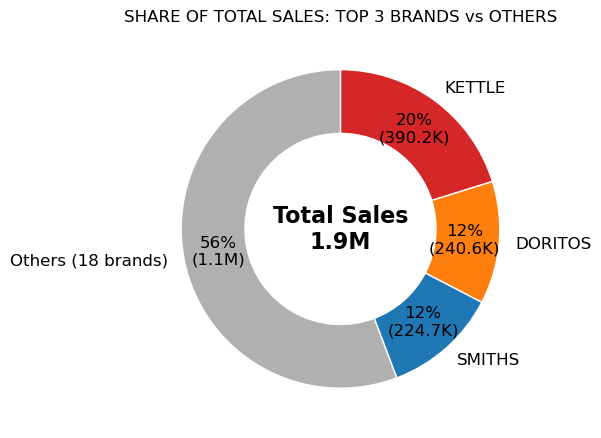

In [14]:

def fmt(v):
    if v >= 1_000_000:
        return f"{v/1_000_000:.1f}M"
    if v >= 1_000:
        return f"{v/1_000:.1f}K"
    return f"{v:.0f}"

# Total sales per brand, highest first
brand_sales = (
    df.groupby("BRAND")["TOT_SALES"].sum()
      .sort_values(ascending=False)
)

total = brand_sales.sum()
top3 = brand_sales.head(3)
others = brand_sales.iloc[3:].sum()
n_others = len(brand_sales) - 3

labels = list(top3.index) + [f"Others ({n_others} brands)"]
values = list(top3.values) + [others]
colors = ["#d62728", "#ff7f0e", "#1f77b4", "#b0b0b0"]

# Percentage is of TOTAL sales (whole business), not of the top 3
def label(pct):
    value = pct * total / 100
    return f"{pct:.0f}%\n({fmt(value)})"

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    values,
    labels=labels,
    autopct=label,
    pctdistance=0.78,
    startangle=90,
    counterclock=False,
    colors=colors,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 12},
)

# Centre text
ax.text(0, 0, f"Total Sales\n{fmt(total)}", ha="center", va="center",
        fontsize=16, fontweight="bold")

plt.title("SHARE OF TOTAL SALES: TOP 3 BRANDS vs OTHERS")
plt.tight_layout()
plt.show()

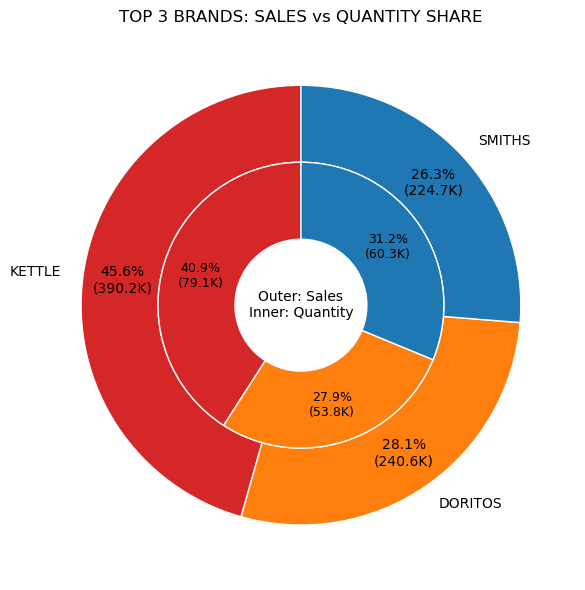

In [15]:
def fmt(v):
    if v >= 1_000_000:
        return f"{v/1_000_000:.1f}M"
    if v >= 1_000:
        return f"{v/1_000:.1f}K"
    return f"{v:.0f}"

# Total sales and quantity per brand, keep only the top 3 by sales
top3 = (
    df.groupby("BRAND", as_index=False)[["TOT_SALES", "PROD_QTY"]]
      .sum()
      .sort_values("TOT_SALES", ascending=False)
      .head(3)
      .reset_index(drop=True)
)

colors = ["#d62728", "#ff7f0e", "#1f77b4"]

def make_label(total):
    def label(pct):
        value = pct * total / 100
        return f"{pct:.1f}%\n({fmt(value)})"
    return label

size = 0.35
fig, ax = plt.subplots(figsize=(6, 6))

# Outer ring: sales share
ax.pie(
    top3["TOT_SALES"],
    radius=1,
    labels=top3["BRAND"],
    autopct=make_label(top3["TOT_SALES"].sum()),
    pctdistance=0.82,
    startangle=90,
    colors=colors,
    wedgeprops={"width": size, "edgecolor": "white"},
    textprops={"fontsize": 10},
)

# Inner ring: quantity share (same brands, same colors)
ax.pie(
    top3["PROD_QTY"],
    radius=1 - size,
    autopct=make_label(top3["PROD_QTY"].sum()),
    pctdistance=0.73,
    startangle=90,
    colors=colors,
    wedgeprops={"width": size, "edgecolor": "white"},
    textprops={"fontsize": 9},
)

# Centre note so the rings are clear
ax.text(0, 0, "Outer: Sales\nInner: Quantity", ha="center", va="center", fontsize=10)

plt.title("TOP 3 BRANDS: SALES vs QUANTITY SHARE")
plt.tight_layout()
plt.show()

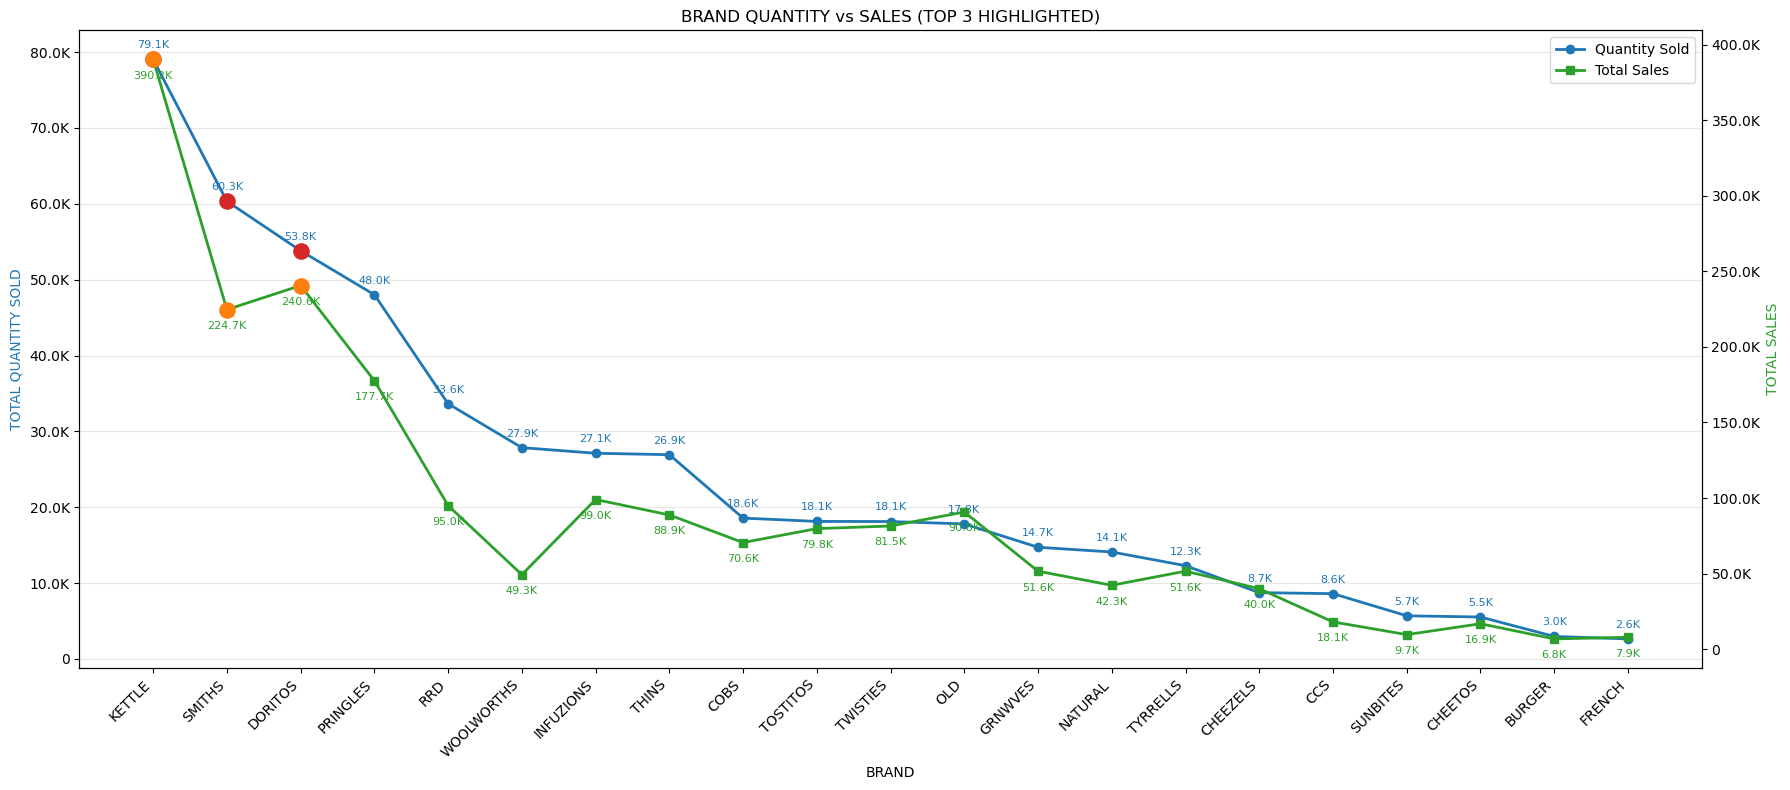

In [16]:


def fmt(v):
    if v >= 1_000_000:
        return f"{v/1_000_000:.1f}M"
    if v >= 1_000:
        return f"{v/1_000:.1f}K"
    return f"{v:.0f}"

# Total quantity and total sales per brand, sorted by quantity
brand = (
    df.groupby("BRAND", as_index=False)[["PROD_QTY", "TOT_SALES"]]
      .sum()
      .sort_values("PROD_QTY", ascending=False)
      .reset_index(drop=True)
)

fig, ax1 = plt.subplots(figsize=(18, 8))

# Quantity line (left axis)
ax1.plot(brand["BRAND"], brand["PROD_QTY"], marker="o",
         color="#1f77b4", linewidth=2, label="Quantity Sold")
top_qty = brand.nlargest(3, "PROD_QTY")
ax1.scatter(top_qty["BRAND"], top_qty["PROD_QTY"], color="#d62728", s=120, zorder=3)
for x, y in zip(brand["BRAND"], brand["PROD_QTY"]):
    ax1.annotate(fmt(y), (x, y), textcoords="offset points",
                 xytext=(0, 8), ha="center", fontsize=8, color="#1f77b4")
ax1.set_xlabel("BRAND")
ax1.set_ylabel("TOTAL QUANTITY SOLD", color="#1f77b4")
ax1.yaxis.set_major_formatter(lambda x, pos: fmt(x))
ax1.tick_params(axis="x", rotation=45)
plt.setp(ax1.get_xticklabels(), ha="right")

# Sales line (right axis, because sales and quantity have different scales)
ax2 = ax1.twinx()
ax2.plot(brand["BRAND"], brand["TOT_SALES"], marker="s",
         color="#2ca02c", linewidth=2, label="Total Sales")
top_sales = brand.nlargest(3, "TOT_SALES")
ax2.scatter(top_sales["BRAND"], top_sales["TOT_SALES"], color="#ff7f0e", s=120, zorder=3)
for x, y in zip(brand["BRAND"], brand["TOT_SALES"]):
    ax2.annotate(fmt(y), (x, y), textcoords="offset points",
                 xytext=(0, -14), ha="center", fontsize=8, color="#2ca02c")
ax2.set_ylabel("TOTAL SALES", color="#2ca02c")
ax2.yaxis.set_major_formatter(lambda x, pos: fmt(x))

# One combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")

plt.title("BRAND QUANTITY vs SALES (TOP 3 HIGHLIGHTED)")
ax1.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

               TOTAL   KETTLE  SHARE
MONTH                               
2018-07-01  165275.3  33271.0   20.1
2018-08-01  158081.0  32208.8   20.4
2018-09-01  160522.0  32799.8   20.4
2018-10-01  164415.7  32840.8   20.0
2018-11-01  160233.7  32621.4   20.4
2018-12-01  167913.4  33790.6   20.1
2019-01-01  162642.3  32648.0   20.1
2019-02-01  150665.0  29760.6   19.8
2019-03-01  166265.2  33673.6   20.3
2019-04-01  159845.1  32678.4   20.4
2019-05-01  156717.6  31148.6   19.9
2019-06-01  160538.6  32798.2   20.4
Average Kettle share: 20.2%
Lowest: 19.8%  |  Highest: 20.4%


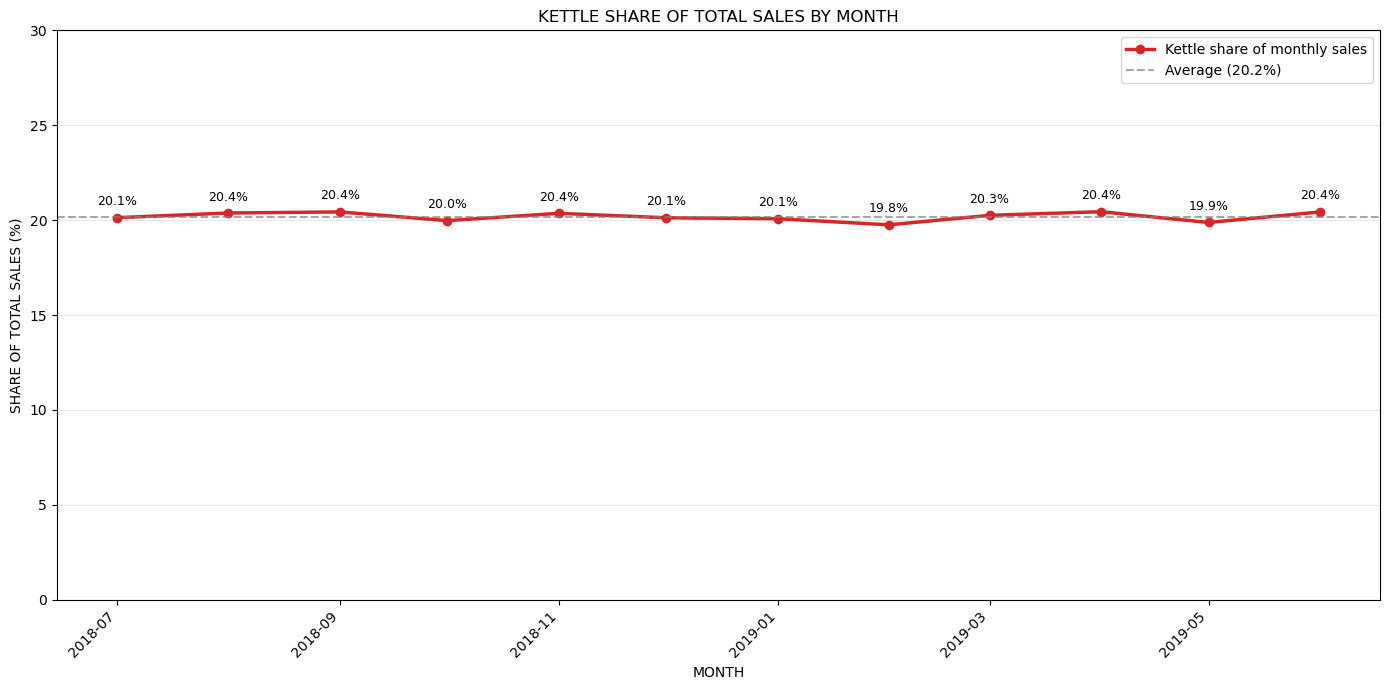

In [17]:


# Fix DATE: Excel serial numbers (like 43390) become real dates
if pd.api.types.is_numeric_dtype(df["DATE"]):
    df["DATE"] = pd.to_datetime(df["DATE"], unit="D", origin="1899-12-30")
else:
    df["DATE"] = pd.to_datetime(df["DATE"])
df["MONTH"] = df["DATE"].dt.to_period("M").dt.to_timestamp()

# Monthly total sales (all brands) and Kettle sales
total = df.groupby("MONTH")["TOT_SALES"].sum()
kettle = df[df["BRAND"].str.upper() == "KETTLE"].groupby("MONTH")["TOT_SALES"].sum()

trend = pd.DataFrame({"TOTAL": total, "KETTLE": kettle}).fillna(0)
trend["SHARE"] = trend["KETTLE"] / trend["TOTAL"] * 100
avg = trend["SHARE"].mean()

print(trend.round(1))
print(f"Average Kettle share: {avg:.1f}%")
print(f"Lowest: {trend['SHARE'].min():.1f}%  |  Highest: {trend['SHARE'].max():.1f}%")

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(trend.index, trend["SHARE"], marker="o", linewidth=2.5, color="#d62728",
        label="Kettle share of monthly sales")
ax.axhline(avg, color="grey", linestyle="--", alpha=0.7, label=f"Average ({avg:.1f}%)")

# Value labels on each point
for x, y in zip(trend.index, trend["SHARE"]):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=9)

# Start the y-axis at 0 so small changes are not exaggerated
ax.set_ylim(0, max(30, trend["SHARE"].max() + 5))
ax.set_title("KETTLE SHARE OF TOTAL SALES BY MONTH")
ax.set_xlabel("MONTH")
ax.set_ylabel("SHARE OF TOTAL SALES (%)")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Total revenue stores : 269
Stores making 40%   : 59
Share of stores      : 21.9%
Their revenue        : 769.3K


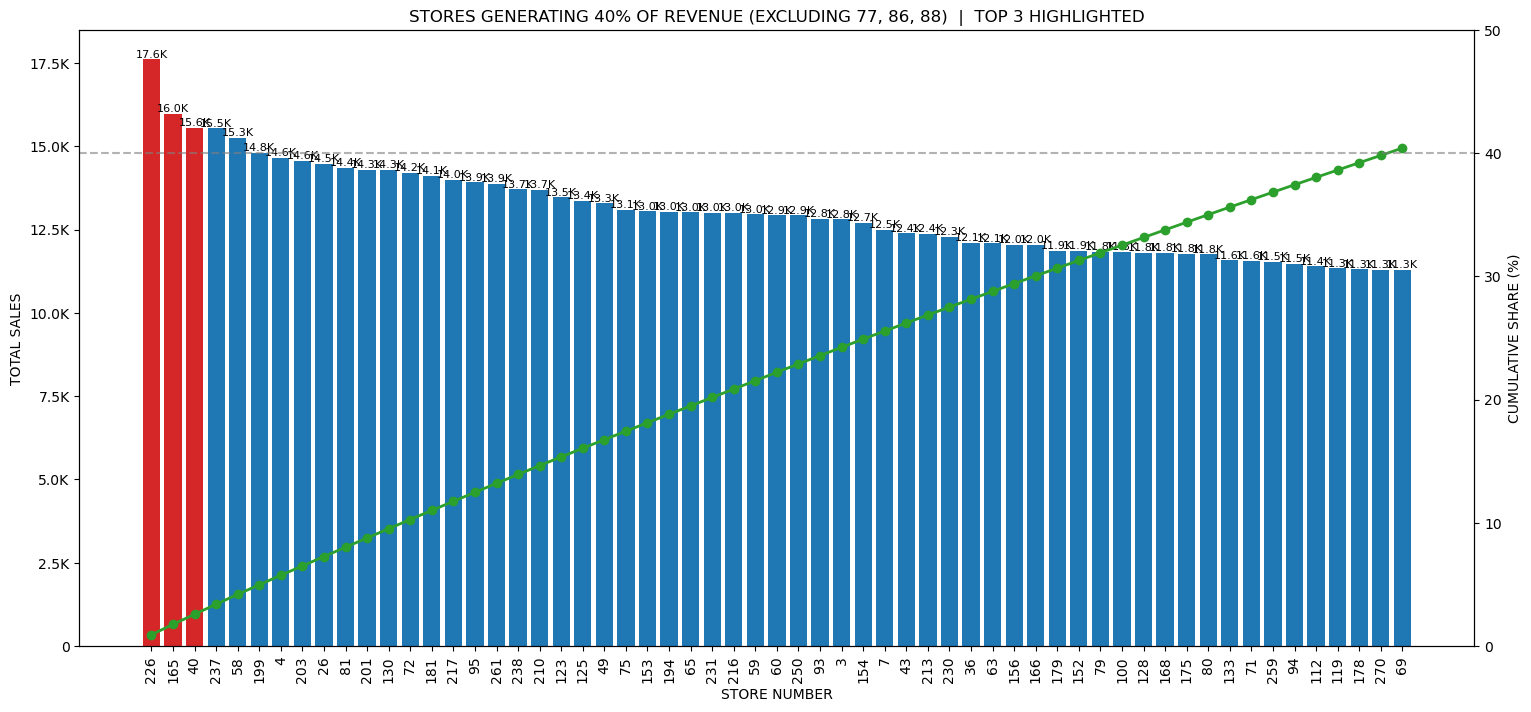

In [18]:
def fmt(v):
    if v >= 1_000_000:
        return f"{v/1_000_000:.1f}M"
    if v >= 1_000:
        return f"{v/1_000:.1f}K"
    return f"{v:.0f}"

THRESHOLD = 40   # kitne % revenue tak ke stores dikhane hain

# Store 77, 86, 88 hatao
excluded = [77, 86, 88]
df_stores = df[~df["STORE_NBR"].isin(excluded)]

# Har store ki total sales (sirf revenue wale stores)
store_sales = (
    df_stores.groupby("STORE_NBR", as_index=False)["TOT_SALES"]
      .sum()
      .sort_values("TOT_SALES", ascending=False)
      .reset_index(drop=True)
)
store_sales = store_sales[store_sales["TOT_SALES"] > 0].reset_index(drop=True)

# Cumulative share
total_sales = store_sales["TOT_SALES"].sum()
store_sales["SHARE"] = store_sales["TOT_SALES"] / total_sales * 100
store_sales["CUM_SHARE"] = store_sales["SHARE"].cumsum()

# Wo stores jo milkar THRESHOLD% revenue banate hain
core = store_sales[store_sales["CUM_SHARE"].shift(fill_value=0) < THRESHOLD].reset_index(drop=True)

print("Total revenue stores :", len(store_sales))
print(f"Stores making {THRESHOLD}%   :", len(core))
print("Share of stores      :", f"{len(core)/len(store_sales)*100:.1f}%")
print("Their revenue        :", fmt(core['TOT_SALES'].sum()))

# Top 3 laal, baaki neela
colors = ["#d62728" if i < 3 else "#1f77b4" for i in range(len(core))]

fig, ax1 = plt.subplots(figsize=(18, 8))
bars = ax1.bar(core["STORE_NBR"].astype(str), core["TOT_SALES"], color=colors)
ax1.bar_label(bars, labels=[fmt(v) for v in core["TOT_SALES"]], fontsize=8)
ax1.set_xlabel("STORE NUMBER")
ax1.set_ylabel("TOTAL SALES")
ax1.yaxis.set_major_formatter(lambda x, pos: fmt(x))
plt.setp(ax1.get_xticklabels(), rotation=90)

# Cumulative % line
ax2 = ax1.twinx()
ax2.plot(core["STORE_NBR"].astype(str), core["CUM_SHARE"],
         color="#2ca02c", marker="o", linewidth=2)
ax2.axhline(THRESHOLD, color="grey", linestyle="--", alpha=0.6)
ax2.set_ylabel("CUMULATIVE SHARE (%)")
ax2.set_ylim(0, THRESHOLD + 10)

plt.title(f"STORES GENERATING {THRESHOLD}% OF REVENUE (EXCLUDING 77, 86, 88)  |  TOP 3 HIGHLIGHTED")
plt.show()

   STORE_NBR  TOT_SALES  PROD_QTY     SHARE
0         88   16333.25      3718  0.844919
1         86   10635.35      3066  0.550166
2         77    3040.00       872  0.157259
Combined sales : 30.0K
Combined share : 1.55% of total revenue


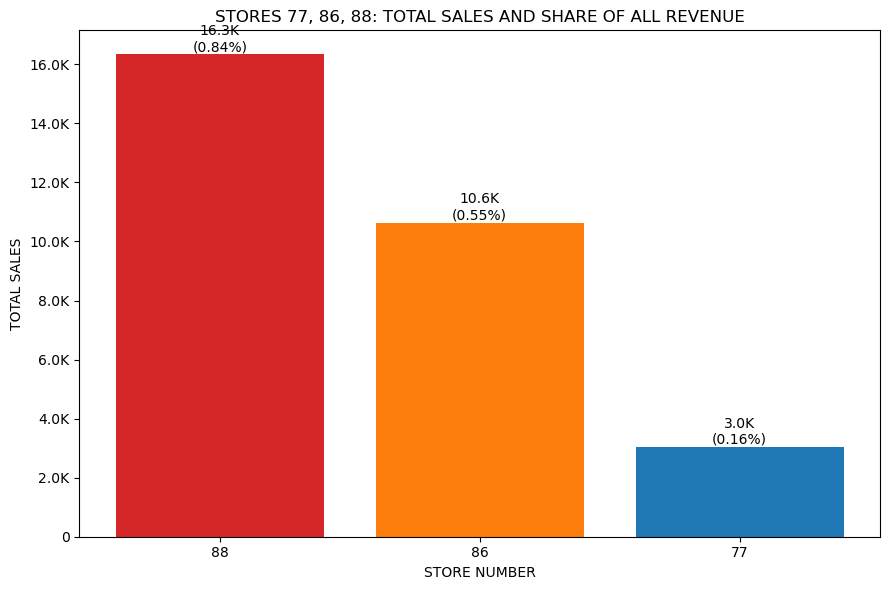

In [19]:
def fmt(v):
    if v >= 1_000_000:
        return f"{v/1_000_000:.1f}M"
    if v >= 1_000:
        return f"{v/1_000:.1f}K"
    return f"{v:.0f}"

selected = [77, 86, 88]

# Total sales and quantity for all stores (to calculate share)
all_stores = df.groupby("STORE_NBR", as_index=False)[["TOT_SALES", "PROD_QTY"]].sum()
total_sales = all_stores["TOT_SALES"].sum()

# Only stores 77, 86, 88
sel = (
    all_stores[all_stores["STORE_NBR"].isin(selected)]
      .sort_values("TOT_SALES", ascending=False)
      .reset_index(drop=True)
)
sel["SHARE"] = sel["TOT_SALES"] / total_sales * 100

print(sel)
print("Combined sales :", fmt(sel["TOT_SALES"].sum()))
print("Combined share :", f"{sel['SHARE'].sum():.2f}% of total revenue")

colors = ["#d62728", "#ff7f0e", "#1f77b4"]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(sel["STORE_NBR"].astype(str), sel["TOT_SALES"], color=colors[:len(sel)])
ax.bar_label(
    bars,
    labels=[f"{fmt(v)}\n({s:.2f}%)" for v, s in zip(sel["TOT_SALES"], sel["SHARE"])],
    fontsize=10,
)
ax.set_title("STORES 77, 86, 88: TOTAL SALES AND SHARE OF ALL REVENUE")
ax.set_xlabel("STORE NUMBER")
ax.set_ylabel("TOTAL SALES")
ax.yaxis.set_major_formatter(lambda x, pos: fmt(x))
plt.tight_layout()
plt.savefig("stores_77_86_88.png", dpi=150)
plt.show()

           PRE_AVG  TRIAL_AVG  CHANGE_%
STORE_NBR                              
77           242.7      259.0       6.7
86           874.3      929.4       6.3
88          1340.5     1428.9       6.6


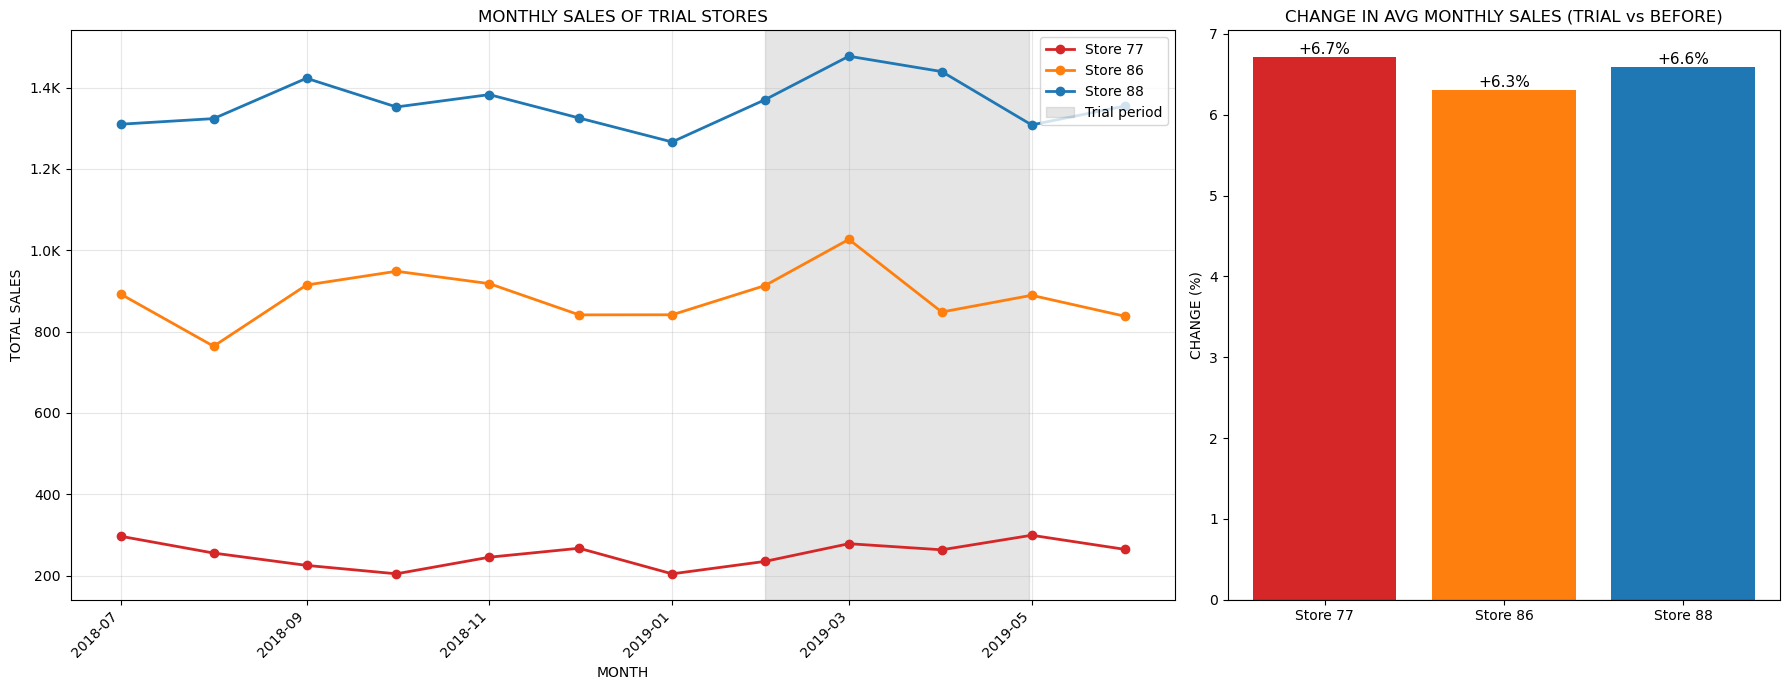

In [20]:
def fmt(v):
    if v >= 1_000_000:
        return f"{v/1_000_000:.1f}M"
    if v >= 1_000:
        return f"{v/1_000:.1f}K"
    return f"{v:.0f}"

trial_stores = [77, 86, 88]
TRIAL_START = "2019-02-01" 
TRIAL_END   = "2019-04-30"  
if pd.api.types.is_numeric_dtype(df["DATE"]):
    df["DATE"] = pd.to_datetime(df["DATE"], unit="D", origin="1899-12-30")
else:
    df["DATE"] = pd.to_datetime(df["DATE"])
df["MONTH"] = df["DATE"].dt.to_period("M").dt.to_timestamp()


monthly = (
    df[df["STORE_NBR"].isin(trial_stores)]
      .groupby(["MONTH", "STORE_NBR"])["TOT_SALES"].sum()
      .unstack("STORE_NBR")[trial_stores]
)

t_start, t_end = pd.Timestamp(TRIAL_START), pd.Timestamp(TRIAL_END)
pre   = monthly[monthly.index < t_start]
trial = monthly[(monthly.index >= t_start) & (monthly.index <= t_end)]


summary = pd.DataFrame({
    "PRE_AVG":   pre.mean(),
    "TRIAL_AVG": trial.mean(),
})
summary["CHANGE_%"] = (summary["TRIAL_AVG"] / summary["PRE_AVG"] - 1) * 100
print(summary.round(1))

colors = {77: "#d62728", 86: "#ff7f0e", 88: "#1f77b4"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [2, 1]})


for s in trial_stores:
    ax1.plot(monthly.index, monthly[s], marker="o", linewidth=2,
             color=colors[s], label=f"Store {s}")
ax1.axvspan(t_start, t_end, color="grey", alpha=0.2, label="Trial period")
ax1.set_title("MONTHLY SALES OF TRIAL STORES")
ax1.set_xlabel("MONTH")
ax1.set_ylabel("TOTAL SALES")
ax1.yaxis.set_major_formatter(lambda x, pos: fmt(x))
ax1.grid(alpha=0.3)
ax1.legend()
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")

bars = ax2.bar([f"Store {s}" for s in summary.index], summary["CHANGE_%"],
               color=[colors[s] for s in summary.index])
ax2.bar_label(bars, labels=[f"{v:+.1f}%" for v in summary["CHANGE_%"]], fontsize=11)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("CHANGE IN AVG MONTHLY SALES (TRIAL vs BEFORE)")
ax2.set_ylabel("CHANGE (%)")

plt.tight_layout()
plt.savefig("trial_stores_before_after.png", dpi=150)
plt.show()

In [21]:
"""
Store overview (Section A): all stores, descriptive only. No charts, only tables.

Answers
  Q1  How many stores are there, and what are each store's sales, quantity and
      customers (plus the spread: min / median / max)?
  Q2  How many stores bring half of total sales?
  Q3  Per store: price per unit, transactions per customer, units per transaction.

It also adds `months_active` per store, which you need later to decide which
stores are "meaningful" (for example, stores with the full 12 months of data).

Outputs (saved next to this script)
  store_overview.csv           one row per store with all metrics
  store_overview_summary.csv   min / quartiles / median / max of each metric
  store_concentration.csv      stores ranked by sales with cumulative share

Edit the CONFIG block if your file or column names differ.
"""
import math


# ----------------------------- CONFIG ---------------------------------
DATA_FILE = "QVI_data.csv"      # merged transaction + customer file
COL_DATE = "DATE"
COL_STORE = "STORE_NBR"
COL_CUST = "LYLTY_CARD_NBR"
COL_TXN = "TXN_ID"
COL_QTY = "PROD_QTY"
COL_SALES = "TOT_SALES"
TRIAL_STORES = [77, 86, 88]     # only marked in the output, not analysed here
OUT_STORES = "store_overview.csv"
OUT_SUMMARY = "store_overview_summary.csv"
OUT_CONC = "store_concentration.csv"
# -----------------------------------------------------------------------

df = pd.read_csv(DATA_FILE)

# Dates: Excel serial numbers (raw file) or normal date text (merged file)
if pd.api.types.is_numeric_dtype(df[COL_DATE]):
    df[COL_DATE] = pd.to_datetime(df[COL_DATE], unit="D", origin="1899-12-30")
else:
    df[COL_DATE] = pd.to_datetime(df[COL_DATE])
df["MONTH"] = df[COL_DATE].dt.to_period("M")

# A transaction is one customer card on one TXN_ID; TXN_ID alone is not always unique.
df["TXN_KEY"] = df[COL_CUST].astype(str) + "_" + df[COL_TXN].astype(str)

# ------------------------------ quick checks ---------------------------
n_months = df["MONTH"].nunique()
print(f"Rows: {len(df):,}")
print(f"Date range: {df[COL_DATE].min().date()} to {df[COL_DATE].max().date()} ({n_months} months)")
print("Missing values in key columns:")
print(df[[COL_STORE, COL_CUST, COL_TXN, COL_QTY, COL_SALES]].isna().sum().to_string())

# ------------------------- Q1 + Q3: per-store table --------------------
g = df.groupby(COL_STORE)
stores = pd.DataFrame({
    "total_sales": g[COL_SALES].sum(),
    "total_qty": g[COL_QTY].sum(),
    "customers": g[COL_CUST].nunique(),
    "transactions": g["TXN_KEY"].nunique(),
    "months_active": g["MONTH"].nunique(),
})
stores["price_per_unit"] = stores["total_sales"] / stores["total_qty"]
stores["txn_per_customer"] = stores["transactions"] / stores["customers"]
stores["units_per_txn"] = stores["total_qty"] / stores["transactions"]
stores["is_trial"] = stores.index.isin(TRIAL_STORES)
stores = stores.sort_values("total_sales", ascending=False)
stores.insert(0, "sales_rank", range(1, len(stores) + 1))

print(f"\nNumber of stores: {len(stores)}")
print(f"Stores with all {n_months} months of data: {(stores['months_active'] == n_months).sum()}")
print(f"Stores with fewer months: {(stores['months_active'] < n_months).sum()}")

metrics = ["total_sales", "total_qty", "customers", "transactions",
           "price_per_unit", "txn_per_customer", "units_per_txn"]
summary = stores[metrics].describe(percentiles=[0.25, 0.5, 0.75]).round(2)
print("\nSpread across all stores (min / 25% / median / 75% / max):")
print(summary.to_string())

# ------------------------------ Q2: concentration ----------------------
total = stores["total_sales"].sum()
conc = stores[["sales_rank", "total_sales"]].copy()
conc["share"] = conc["total_sales"] / total
conc["cumulative_share"] = conc["share"].cumsum()

n_stores = len(conc)
n_half = int((conc["cumulative_share"] < 0.5).sum() + 1)
top10_n = math.ceil(0.10 * n_stores)
top10_share = conc["share"].head(top10_n).sum()
print(f"\n{n_half} of {n_stores} stores ({n_half / n_stores:.0%}) bring 50% of total sales.")
print(f"The top 10% of stores ({top10_n} stores) bring {top10_share:.0%} of total sales.")
print(f"The biggest store brings {conc['share'].iloc[0]:.1%}; the smallest brings {conc['share'].iloc[-1]:.2%}.")

# ------------------------------ save ----------------------------------
stores.round(4).to_csv(OUT_STORES)
summary.to_csv(OUT_SUMMARY)
conc.round(6).to_csv(OUT_CONC)
print(f"\nSaved: {OUT_STORES}, {OUT_SUMMARY}, {OUT_CONC}")

Rows: 264,834
Date range: 2018-07-01 to 2019-06-30 (12 months)
Missing values in key columns:
STORE_NBR         0
LYLTY_CARD_NBR    0
TXN_ID            0
PROD_QTY          0
TOT_SALES         0

Number of stores: 272
Stores with all 12 months of data: 260
Stores with fewer months: 12

Spread across all stores (min / 25% / median / 75% / max):
       total_sales  total_qty  customers  transactions  price_per_unit  txn_per_customer  units_per_txn
count       272.00     272.00     272.00        272.00          272.00            272.00         272.00
mean       7107.04    1855.60     267.05        967.38            3.80              3.49           1.80
std        4705.86    1215.10      97.75        582.20            0.46              2.06           0.30
min           5.20       2.00       1.00          1.00            2.60              1.00           1.00
25%        2899.42     817.25     245.00        528.25            3.48              1.66           1.66
50%        5972.62    1353.50  

In [22]:

# ---------------- SETTINGS ----------------
N_SPOT = 5                  # har hisse se kitne stores (4, 5, 8 ...)
TRIAL = [77, 86, 88]
# ------------------------------------------

data = df.copy()            # apna data; original df ko haath nahi lagta
data["DATE"] = pd.to_datetime(data["DATE"])
data["MONTH"] = data["DATE"].dt.to_period("M").astype(str)

# 1) store table: sales, qty, customers, months, price
g = data.groupby("STORE_NBR")
stores = pd.DataFrame({
    "total_sales":   g["TOT_SALES"].sum(),
    "total_qty":     g["PROD_QTY"].sum(),
    "customers":     g["LYLTY_CARD_NBR"].nunique(),
    "months_active": g["MONTH"].nunique(),
})
stores["price_per_unit"] = stores["total_sales"] / stores["total_qty"]
stores["sales_rank"] = stores["total_sales"].rank(ascending=False, method="first").astype(int)

# sirf poore 12 mahine wale stores, 3 hisse
pool = stores[stores["months_active"] == 12].copy()
pool["tier"] = pd.qcut(pool["total_sales"].rank(method="first"), 3,
                       labels=["Low", "Medium", "Top"])
print(pool.groupby("tier", observed=True)["total_sales"]
          .agg(["count", "min", "median", "max"]).round(0))

# 2) store x month sales/qty
data = data[data["STORE_NBR"].isin(pool.index)]
m = data.groupby(["STORE_NBR", "MONTH"]).agg(
    sales=("TOT_SALES", "sum"), qty=("PROD_QTY", "sum")).reset_index()
m["tier"] = m["STORE_NBR"].map(pool["tier"])

# 3) har hisse ka AVERAGE store, mahine ke hisaab se
tier_month = m.groupby(["tier", "MONTH"], observed=True).agg(
    avg_sales=("sales", "mean"), avg_qty=("qty", "mean")).round(0).reset_index()
print("\nAverage store monthly sales per tier:")
print(tier_month.pivot(index="MONTH", columns="tier", values="avg_sales"))

# 4) har hisse se N_SPOT khaas stores
top = pool[pool["tier"] == "Top"].nlargest(N_SPOT, "total_sales").index
low = pool[pool["tier"] == "Low"].nsmallest(N_SPOT, "total_sales").index
mid = pool[pool["tier"] == "Medium"]
med = (mid["total_sales"] - mid["total_sales"].median()).abs().nsmallest(N_SPOT).index

groups = {"Top": list(top), "Medium (median ke paas)": list(med),
          "Low": list(low), "Trial": TRIAL}
for name, ids in groups.items():
    print(f"\n{name}:")
    print(pool.loc[ids, ["sales_rank", "total_sales", "total_qty", "customers",
                         "price_per_unit"]].round(2).to_string())

# 5) khaas stores ka store x month sales table
spot_ids = [s for ids in groups.values() for s in ids]
spot = m[m["STORE_NBR"].isin(spot_ids)].pivot(index="STORE_NBR", columns="MONTH", values="sales")
print("\nSpotlight stores, monthly sales:")
print(spot.round(0).to_string())

        count      min   median      max
tier                                    
Low        87    211.0   2519.0   4266.0
Medium     86   4306.0   9101.0  10472.0
Top        87  10485.0  11865.0  17605.0

Average store monthly sales per tier:
tier       Low  Medium     Top
MONTH                         
2018-07  191.0   646.0  1069.0
2018-08  188.0   638.0   997.0
2018-09  183.0   636.0  1033.0
2018-10  186.0   656.0  1054.0
2018-11  185.0   634.0  1028.0
2018-12  194.0   675.0  1068.0
2019-01  182.0   657.0  1038.0
2019-02  168.0   587.0   983.0
2019-03  192.0   661.0  1065.0
2019-04  176.0   642.0  1026.0
2019-05  197.0   619.0   991.0
2019-06  187.0   629.0  1035.0

Top:
           sales_rank  total_sales  total_qty  customers  price_per_unit
STORE_NBR                                                               
226                 1     17605.45       4001        381            4.40
88                  2     16333.25       3718        388            4.39
165                 3   

Q1  Teeno hisson me store ka average pack size:
        count   mean  std    min    25%    50%    75%    max
tier                                                        
Low      87.0  180.5  4.6  167.2  178.1  180.4  183.2  191.8
Medium   86.0  182.8  4.2  175.5  179.8  181.6  185.6  193.8
Top      87.0  183.4  3.4  176.9  180.4  183.2  186.3  189.4

Q2  Rishta (Spearman: -1..+1, 0 = koi rishta nahi), sabhi 260 stores:
          avg_pack  sales  sales_per_customer  customers
avg_pack       1.0   0.27               -0.01       0.46

Q3  Har hisse ke andar avg_pack ka rishta:
  tier  with_sales  with_sales_per_customer
   Top        0.68                    -0.68
Medium       -0.67                    -0.68
   Low        0.26                     0.29

Q4  Price per 100g (pack size hata kar), median:
tier
Low       1.95
Medium    1.97
Top       1.97
Name: price_per_100g, dtype: float64


C:\Users\BILAL AHMAD\AppData\Local\Temp\ipykernel_3692\2024384171.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0, 0].boxplot([st[st["tier"] == t]["avg_pack"] for t in tiers], labels=tiers, showfliers=True)


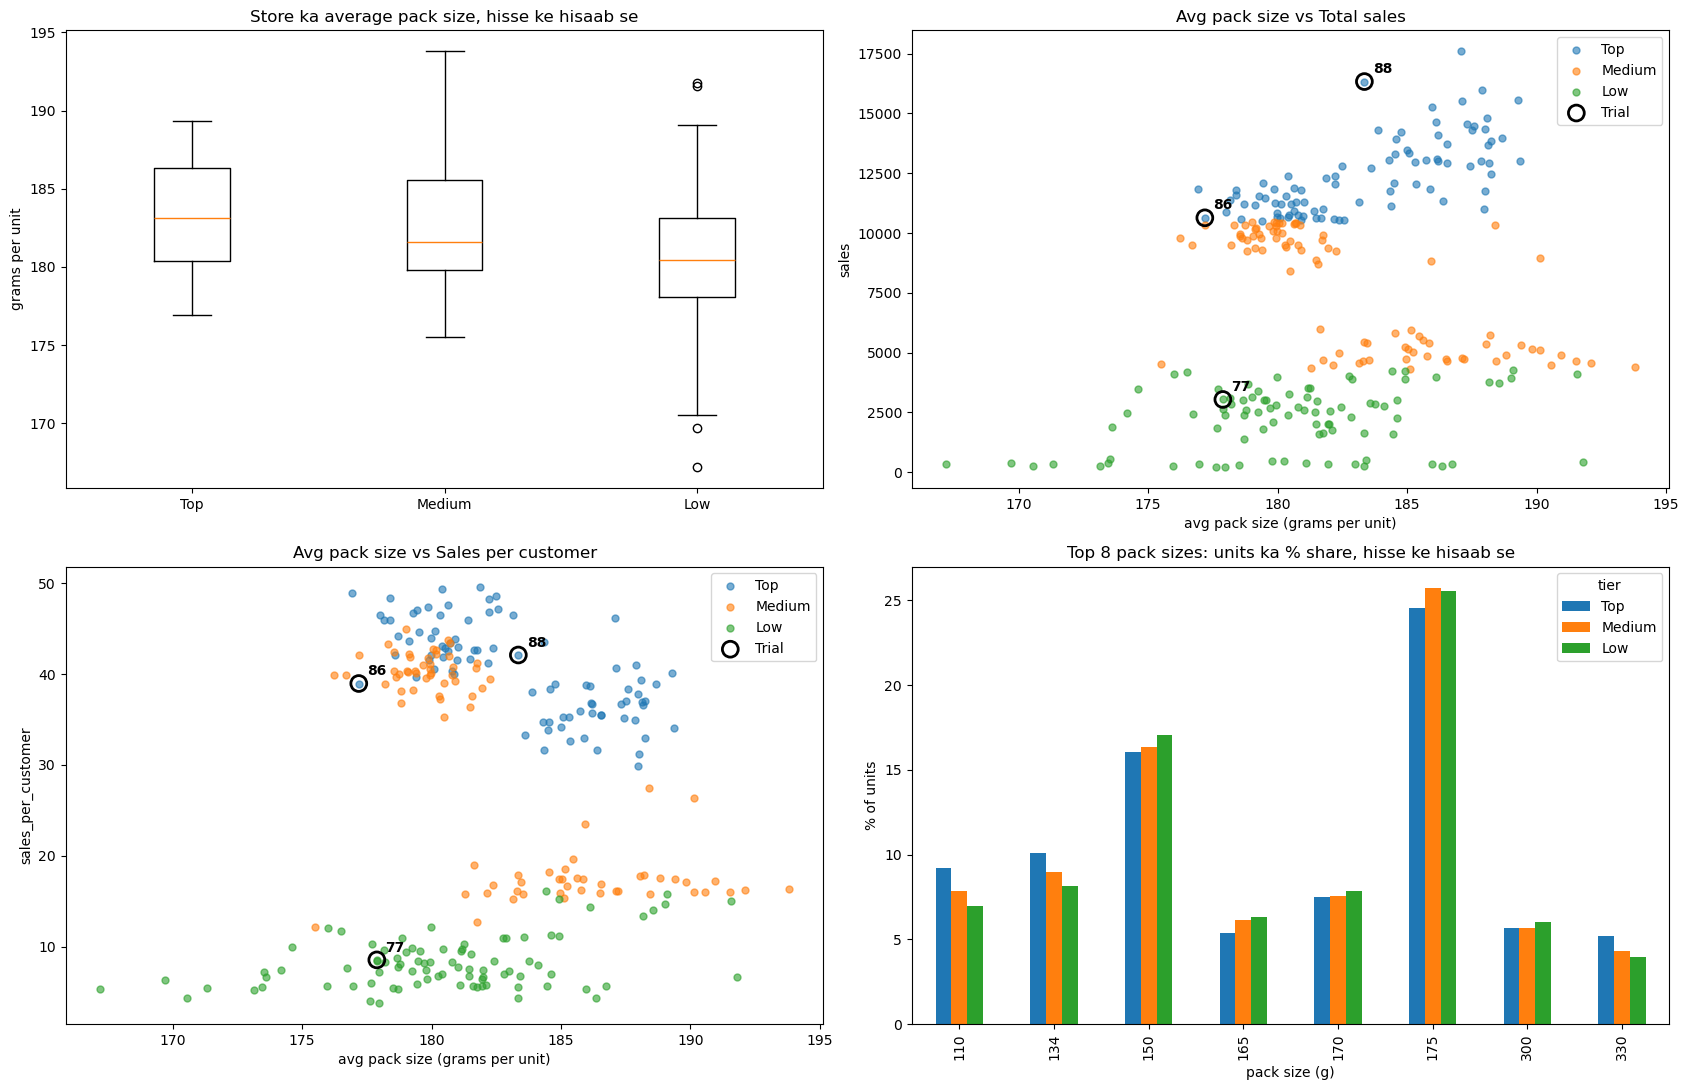

In [23]:

# ---------------- SETTINGS ----------------
PACK = "PACK_SIZE"          # pack size column ka naam
TRIAL = [77, 86, 88]
COL = {"Top": "#1f77b4", "Medium": "#ff7f0e", "Low": "#2ca02c"}
# ------------------------------------------

data = df.copy()                                   # original df safe
data["DATE"] = pd.to_datetime(data["DATE"])
data["MONTH"] = data["DATE"].dt.to_period("M").astype(str)
data["pack_total"] = data[PACK] * data["PROD_QTY"]     # kul grams

# 1) store table (sirf poore 12 mahine wale) + 3 hisse
st = data.groupby("STORE_NBR").agg(
    sales=("TOT_SALES", "sum"), qty=("PROD_QTY", "sum"),
    customers=("LYLTY_CARD_NBR", "nunique"), months=("MONTH", "nunique"),
    pack_total=("pack_total", "sum"))
st = st[st["months"] == 12].copy()
st["tier"] = pd.qcut(st["sales"].rank(method="first"), 3, labels=["Low", "Medium", "Top"])
st["avg_pack"] = st["pack_total"] / st["qty"]                       # grams per unit
st["sales_per_customer"] = st["sales"] / st["customers"]            # store size hata kar
st["price_per_100g"] = st["sales"] / st["pack_total"] * 100         # pack size hata kar
data["tier"] = data["STORE_NBR"].map(st["tier"])
data = data[data["tier"].notna()]

# 2) NUMBERS
print("Q1  Teeno hisson me store ka average pack size:")
print(st.groupby("tier", observed=True)["avg_pack"].describe().round(1))

print("\nQ2  Rishta (Spearman: -1..+1, 0 = koi rishta nahi), sabhi 260 stores:")
print(st[["avg_pack", "sales", "sales_per_customer", "customers"]]
      .corr(method="spearman").round(2).loc[["avg_pack"]])

print("\nQ3  Har hisse ke andar avg_pack ka rishta:")
rows = []
for t in ["Top", "Medium", "Low"]:
    x = st[st["tier"] == t]
    rows.append([t, round(x["avg_pack"].corr(x["sales"], method="spearman"), 2),
                 round(x["avg_pack"].corr(x["sales_per_customer"], method="spearman"), 2)])
print(pd.DataFrame(rows, columns=["tier", "with_sales", "with_sales_per_customer"]).to_string(index=False))

print("\nQ4  Price per 100g (pack size hata kar), median:")
print(st.groupby("tier", observed=True)["price_per_100g"].median().round(2))

# 3) CHARTS (2 x 2)
fig, ax = plt.subplots(2, 2, figsize=(17, 11))
tiers = ["Top", "Medium", "Low"]

# (a) avg pack size har hisse me
ax[0, 0].boxplot([st[st["tier"] == t]["avg_pack"] for t in tiers], labels=tiers, showfliers=True)
ax[0, 0].set_title("Store ka average pack size, hisse ke hisaab se")
ax[0, 0].set_ylabel("grams per unit")

# (b) avg pack vs total sales
# (c) avg pack vs sales per customer
for a, ycol, ttl in [(ax[0, 1], "sales", "Avg pack size vs Total sales"),
                     (ax[1, 0], "sales_per_customer", "Avg pack size vs Sales per customer")]:
    for t in tiers:
        x = st[st["tier"] == t]
        a.scatter(x["avg_pack"], x[ycol], s=25, alpha=0.6, color=COL[t], label=t)
    tr = st.loc[TRIAL]
    a.scatter(tr["avg_pack"], tr[ycol], s=130, facecolors="none", edgecolors="black", lw=2, label="Trial")
    for i, r in tr.iterrows():
        a.annotate(str(i), (r["avg_pack"], r[ycol]), xytext=(6, 6), textcoords="offset points", fontweight="bold")
    a.set_title(ttl); a.set_xlabel("avg pack size (grams per unit)"); a.set_ylabel(ycol)
    a.legend()

# (d) top pack sizes, % of units, hisse ke hisaab se
ps = data.groupby(["tier", PACK], observed=True)["PROD_QTY"].sum().unstack(0)
ps = (ps / ps.sum() * 100)
top_sizes = ps.sum(axis=1).sort_values(ascending=False).head(8).index
ps.loc[sorted(top_sizes), tiers].plot.bar(ax=ax[1, 1], color=[COL[t] for t in tiers])
ax[1, 1].set_title("Top 8 pack sizes: units ka % share, hisse ke hisaab se")
ax[1, 1].set_xlabel("pack size (g)"); ax[1, 1].set_ylabel("% of units")

plt.tight_layout()
plt.savefig("pack_size_analysis.png", dpi=120)
plt.show()

In [24]:
# per-store behaviour
d = data.copy()
d["TXN_KEY"] = d["LYLTY_CARD_NBR"].astype(str) + "_" + d["TXN_ID"].astype(str)
b = d.groupby("STORE_NBR").agg(txns=("TXN_KEY", "nunique"))
st2 = st.join(b)
st2["txn_per_customer"] = st2["txns"] / st2["customers"]
st2["units_per_txn"] = st2["qty"] / st2["txns"]

# sales per customer ke hisaab se 3 gut (apni marzi se cut badal sakte ho)
st2["type"] = pd.cut(st2["sales_per_customer"], [0, 14, 30, 100],
                     labels=["Low spend (<14)", "Mid spend (14-30)", "High spend (>30)"])
print(st2.groupby("type", observed=True).agg(
    stores=("sales", "size"), customers=("customers", "median"),
    sales=("sales", "median"), txn_per_customer=("txn_per_customer", "median"),
    units_per_txn=("units_per_txn", "median"), avg_pack=("avg_pack", "median")).round(2))
print(st2.loc[[77, 86, 88], ["type", "sales_per_customer", "txn_per_customer", "units_per_txn"]].round(2))

                   stores  customers     sales  txn_per_customer  \
type                                                               
Low spend (<14)        82      318.5   2420.55              1.60   
Mid spend (14-30)      47      297.0   4865.00              1.91   
High spend (>30)      131      256.0  11139.50              5.77   

                   units_per_txn  avg_pack  
type                                        
Low spend (<14)             1.46    179.97  
Mid spend (14-30)           1.97    186.12  
High spend (>30)            2.00    180.84  
                       type  sales_per_customer  txn_per_customer  \
STORE_NBR                                                           
77          Low spend (<14)                8.54              1.58   
86         High spend (>30)               38.96              5.59   
88         High spend (>30)               42.10              4.79   

           units_per_txn  
STORE_NBR                 
77                  1.55  
86     

In [26]:
d

,LYLTY_CARD_NBR,DATE,STORE_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES,PACK_SIZE,BRAND,LIFESTAGE,PREMIUM_CUSTOMER,MONTH,TXN_KEY,pack_total,tier
0,1000,2018-10-17,1,1,5,Natural Chip Compny SeaSalt175g,2,6.0,175,NATURAL,YOUNG SINGLES/COUPLES,Premium,2018-10,1000_1,350,Low
1,1002,2018-09-16,1,2,58,Red Rock Deli Chikn&Garlic Aioli 150g,1,2.7,150,RRD,YOUNG SINGLES/COUPLES,Mainstream,2018-09,1002_2,150,Low
2,1003,2019-03-07,1,3,52,Grain Waves Sour Cream&Chives 210G,1,3.6,210,GRNWVES,YOUNG FAMILIES,Budget,2019-03,1003_3,210,Low
3,1003,2019-03-08,1,4,106,Natural ChipCo Hony Soy Chckn175g,1,3.0,175,NATURAL,YOUNG FAMILIES,Budget,2019-03,1003_4,175,Low
4,1004,2018-11-02,1,5,96,WW Original Stacked Chips 160g,1,1.9,160,WOOLWORTHS,OLDER SINGLES/COUPLES,Mainstream,2018-11,1004_5,160,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264829,2370701,2018-12-08,88,240378,24,Grain Waves Sweet Chilli 210g,2,7.2,210,GRNWVES,YOUNG FAMILIES,Mainstream,2018-12,2370701_240378,420,Top
264830,2370751,2018-10-01,88,240394,60,Kettle Tortilla ChpsFeta&Garlic 150g,2,9.2,150,KETTLE,YOUNG FAMILIES,Premium,2018-10,2370751_240394,300,Top
264831,2370961,2018-10-24,88,240480,70,Tyrrells Crisps Lightly Salted 165g,2,8.4,165,TYRRELLS,OLDER FAMILIES,Budget,2018-10,2370961_240480,330,Top
264832,2370961,2018-10-27,88,240481,65,Old El Paso Salsa Dip Chnky Tom Ht300g,2,10.2,300,OLD,OLDER FAMILIES,Budget,2018-10,2370961_240481,600,Top


                            sales     qty  customers  sales_share_%  qty_share_%  price_per_unit  sales_per_customer  sales_rank  qty_rank
LIFESTAGE                                                                                                                                 
OLDER SINGLES/COUPLES   402426.75  104203      14609           20.8         20.6            3.86               27.55           1         1
RETIREES                366470.90   94166      14805           19.0         18.7            3.89               24.75           2         3
OLDER FAMILIES          352467.20   94592       9779           18.2         18.7            3.73               36.04           3         2
YOUNG FAMILIES          316160.10   84561       9178           16.4         16.8            3.74               34.45           4         4
YOUNG SINGLES/COUPLES   260405.30   66634      14441           13.5         13.2            3.91               18.03           5         5
MIDAGE SINGLES/COUPLES  184

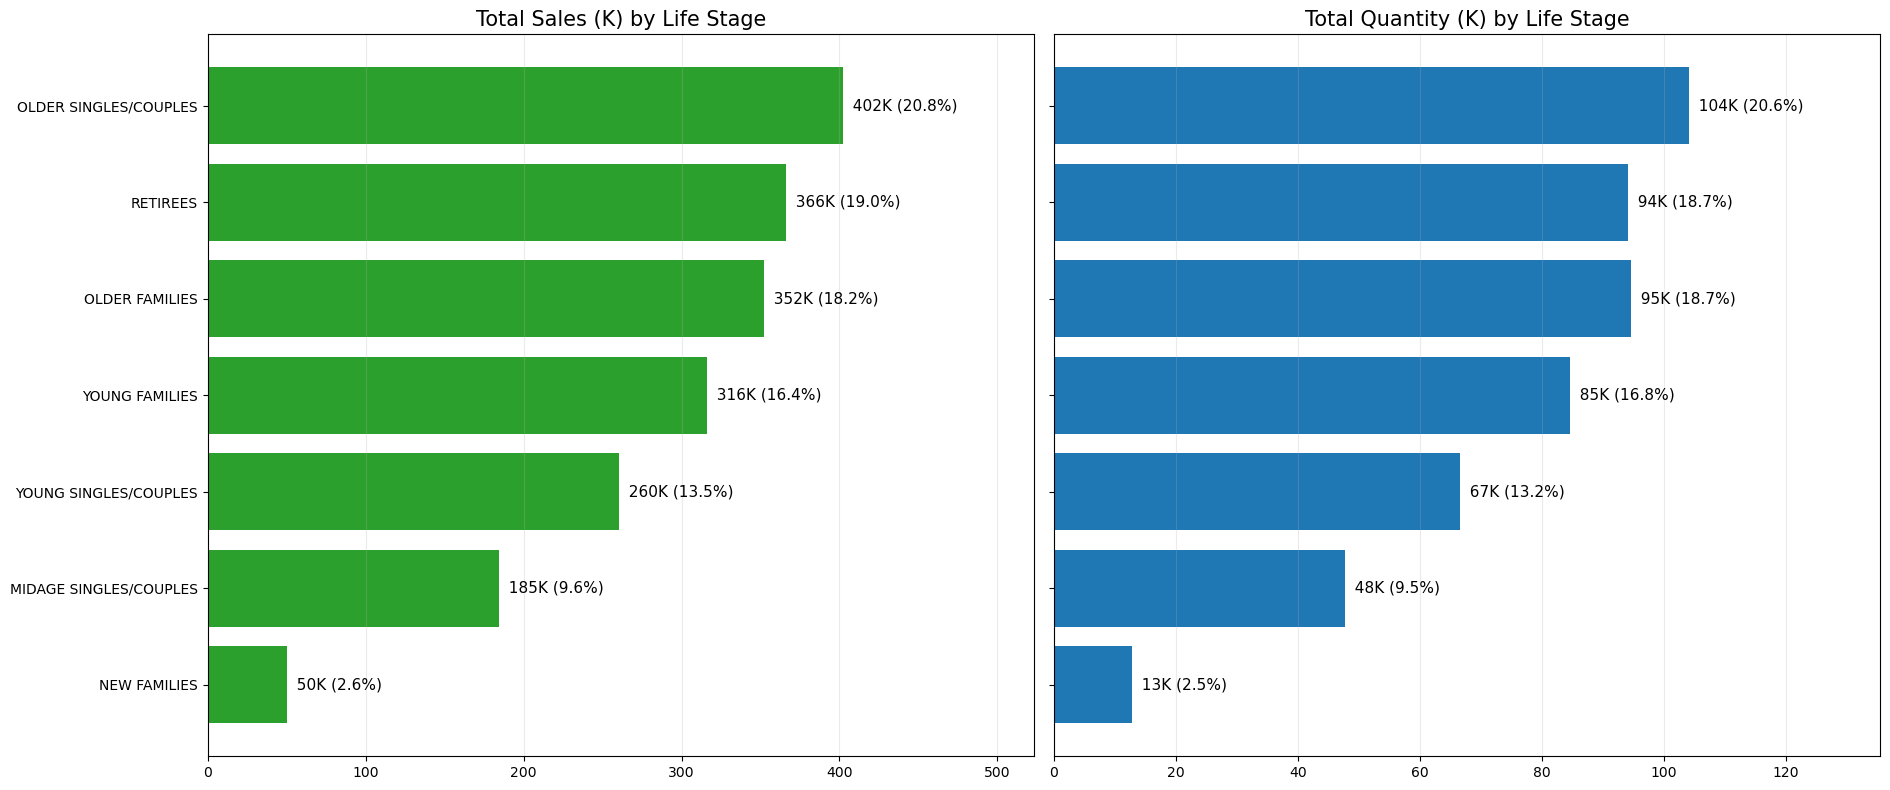

In [27]:

g = df.groupby("LIFESTAGE").agg(
    sales=("TOT_SALES", "sum"), qty=("PROD_QTY", "sum"),
    customers=("LYLTY_CARD_NBR", "nunique"))
g["sales_share_%"] = (g["sales"] / g["sales"].sum() * 100).round(1)
g["qty_share_%"] = (g["qty"] / g["qty"].sum() * 100).round(1)
g["price_per_unit"] = g["sales"] / g["qty"]
g["sales_per_customer"] = g["sales"] / g["customers"]
g["sales_rank"] = g["sales"].rank(ascending=False).astype(int)
g["qty_rank"] = g["qty"].rank(ascending=False).astype(int)
g = g.sort_values("sales", ascending=False)
print(g.round(2).to_string())

# chart: sales aur quantity, ek hi tarteeb me (bada upar)
order = g.index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(19, 8), sharey=True)
ax[0].barh(order, g.loc[order, "sales"] / 1000, color="#2ca02c")
ax[1].barh(order, g.loc[order, "qty"] / 1000, color="#1f77b4")
for a, col, share in [(ax[0], "sales", "sales_share_%"), (ax[1], "qty", "qty_share_%")]:
    for i, ls in enumerate(order):
        v = g.loc[ls, col] / 1000
        a.text(v, i, f"  {v:,.0f}K ({g.loc[ls, share]}%)", va="center", fontsize=11)
    a.set_xlim(0, g[col].max() / 1000 * 1.3)
    a.grid(axis="x", alpha=0.25)
ax[0].set_title("Total Sales (K) by Life Stage", fontsize=15)
ax[1].set_title("Total Quantity (K) by Life Stage", fontsize=15)
plt.tight_layout()
plt.savefig("lifestage_sales_qty.png", dpi=120)
plt.show()

In [29]:

from scipy.stats import chi2_contingency

BRAND, PACK, LS = "BRAND", "PACK_SIZE", "LIFESTAGE"        # column ke naam
CONTROL = {77: 233, 86: 155, 88: 178}                      # apne Task 2 ke control stores yahan likho

d = df.copy()
d["store_type"] = d["STORE_NBR"].map(st2["type"]).astype(object)    # Low / Mid / High spend
d["size_tier"] = d["STORE_NBR"].map(st2["tier"]).astype(object)     # Top / Medium / Low
d = d[d["store_type"].notna()]                                       # poore 12 mahine wale stores
d["pack_band"] = pd.cut(d[PACK], [0, 150, 200, 1000],
                        labels=["Small (<=150g)", "Medium (151-200g)", "Large (>200g)"])

# 1) Rishte ki taaqat: LIFESTAGE har cheez ke saath kitna juda hai
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    return (chi2_contingency(ct)[0] / (ct.values.sum() * (min(ct.shape) - 1))) ** 0.5

pairs = [("Brand", BRAND), ("Pack size band", "pack_band"),
         ("Store type", "store_type"), ("Store size group", "size_tier")]
print(pd.DataFrame([[n, round(cramers_v(d[LS], d[c]), 3)] for n, c in pairs],
                   columns=["Compared with LIFESTAGE", "Cramers_V"]).to_string(index=False))

# 2) Index table: 100 = overall jaisa, 120+ = zyada, 80 se kam = kam
def index_table(col, keep=None):
    t = pd.crosstab(d[LS], d[col], normalize="index") / d[col].value_counts(normalize=True) * 100
    return t.round(0)[keep] if keep is not None else t.round(0)

print("\nBrand index by LIFESTAGE (top 8 brands):")
print(index_table(BRAND, d[BRAND].value_counts().head(8).index))
print("\nPack size index by LIFESTAGE:")
print(index_table("pack_band"))
print("\nStore type index by LIFESTAGE:")
print(index_table("store_type"))

# 3) Trial aur control stores ka LIFESTAGE mix (sales share %)
ids = [i for pair in CONTROL.items() for i in pair if i in set(d["STORE_NBR"])]
m = d[d["STORE_NBR"].isin(ids)].pivot_table(index=LS, columns="STORE_NBR",
                                            values="TOT_SALES", aggfunc="sum")
print("\nTrial aur control stores: LIFESTAGE sales share (%):")
print((m / m.sum() * 100).round(1)[ids])

Compared with LIFESTAGE  Cramers_V
                  Brand      0.030
         Pack size band      0.016
             Store type      0.168
       Store size group      0.131

Brand index by LIFESTAGE (top 8 brands):
BRAND                   KETTLE  SMITHS  DORITOS  PRINGLES    RRD  WOOLWORTHS  \
LIFESTAGE                                                                      
MIDAGE SINGLES/COUPLES   104.0    98.0    100.0     100.0   96.0        92.0   
NEW FAMILIES             108.0    91.0    107.0     107.0   84.0        86.0   
OLDER FAMILIES            90.0   110.0     94.0      92.0  119.0       118.0   
OLDER SINGLES/COUPLES    104.0    97.0    102.0     103.0   91.0        95.0   
RETIREES                 106.0    94.0    103.0     105.0   89.0        88.0   
YOUNG FAMILIES            92.0   108.0     96.0      93.0  116.0       114.0   
YOUNG SINGLES/COUPLES    104.0    93.0    104.0     107.0   89.0        90.0   

BRAND                   INFUZIONS  THINS  
LIFESTAGE          